# M27: simulated CCD image vs a real observation from Vidojevica

This notebook builds a simulated CCD image of the Dumbbell Nebula (M27) and compares it with a real
60-second I-band image taken with the 1.4 m Milanković telescope at the Astronomical Station Vidojevica.

**Workflow**
1. Load the real image and its plate-solved WCS (astrometry.net), which gives the exact position,
   scale and rotation of the image on the sky.
2. Measure the real image: sky background, noise, stars and seeing (FWHM).
3. Download Gaia DR3 stars in the field and calibrate their brightness against the real image
   (photometric zero point).
4. Build a parametric model of the nebula and measure its brightness in the real image.
5. Simulate the CCD image: seeing blur, sky, noise, hot pixels, cosmic rays, saturation.
6. Compare the simulation with the real image, pixel by pixel and statistically.

The reusable code lives in the `ccdsim` package and is covered by tests in `tests/`.

## 1. Setup

In [3]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS

from ccdsim.catalog import query_gaia
from ccdsim.compare import compare_images
from ccdsim.imaging import (detect_sources, display_limits, estimate_background_noise,
                            estimate_fwhm, normalize_image, radial_profile)
from ccdsim.model import (calibrate_nebula_peak, calibrate_zero_point, m27_nebula_model,
                          place_stars, simulate_ccd, sky_angle_to_pixel_angle)

DATA_PATH = Path("data/M27-0001_I_wcs.fit")   # plate-solved image from astrometry.net
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

M27 = SkyCoord(ra=299.90155 * u.deg, dec=22.7212 * u.deg)
NEBULA_AXIS_PA_DEG = 117.0   # orientation of the model's lobes on the sky (deg east of north)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found - see 'Data' in README.md")

## 2. Load the real observation

The WCS comes from plate-solving the image with astrometry.net. The original FITS header only had the
telescope's nominal pointing, which says nothing about the image's rotation: this image is rotated by
almost 180 degrees, so north points down.

In [5]:
real = np.nan_to_num(fits.getdata(DATA_PATH).astype(float))
header = fits.getheader(DATA_PATH)
wcs = WCS(header).celestial

pixel_scale = float(np.mean([s.to_value(u.arcsec) for s in wcs.proj_plane_pixel_scales()]))
north_angle = sky_angle_to_pixel_angle(wcs, M27, 0.0)

print(f"Object:      {header.get('OBJECT')}")
print(f"Date:        {header.get('DATE-OBS')}")
print(f"Telescope:   {header.get('TELESCOP')} / {header.get('INSTRUME')}")
print(f"Filter:      {header.get('FILTER', '').strip()}   Exposure: {header.get('EXPTIME')} s")
print(f"Image size:  {real.shape[1]} x {real.shape[0]} px")
print(f"Pixel scale: {pixel_scale:.3f} arcsec/px")
print(f"North points at {north_angle:.1f} deg in the pixel grid (90 deg = up)")

Object:      M27
Date:        2026-05-28T00:24:04
Telescope:   Vidojevica ASA AZ1400 / Andor CCD/EMCCD (SDK2)
Filter:      I   Exposure: 60.0 s
Image size:  2048 x 2048 px
Pixel scale: 0.390 arcsec/px
North points at -85.5 deg in the pixel grid (90 deg = up)


## 3. Measure the real image

Background: 2380.0 ADU
Noise:      31.1 ADU
Stars:      2005
FWHM:       4.22 px = 1.65 arcsec


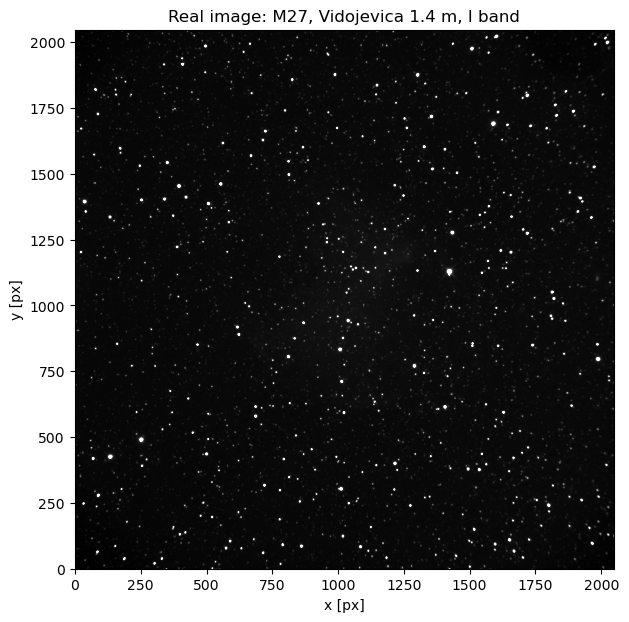

In [7]:
background, noise = estimate_background_noise(real)
xs_real, ys_real = detect_sources(real, background, noise)
fwhm_px = estimate_fwhm(real, xs_real, ys_real)

print(f"Background: {background:.1f} ADU")
print(f"Noise:      {noise:.1f} ADU")
print(f"Stars:      {len(xs_real)}")
print(f"FWHM:       {fwhm_px:.2f} px = {fwhm_px * pixel_scale:.2f} arcsec")

vmin, vmax = display_limits(real)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(real, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
ax.set(title="Real image: M27, Vidojevica 1.4 m, I band", xlabel="x [px]", ylabel="y [px]")
fig.savefig(FIGURES / "real_image.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Gaia DR3 stars and photometric calibration

Each Gaia star is placed on the pixel grid with the real WCS. To give the stars realistic brightness,
the notebook measures isolated, unsaturated stars in the real image with aperture photometry and finds
the zero point `ZP` such that `flux [ADU] = 10^(-0.4 (G - ZP))`.

Gaia's G band is much wider than the I filter, so red and blue stars will scatter around this relation;
a colour term would be the next improvement.

In [9]:
gaia = query_gaia(M27, radius_arcmin=10.0, mag_limit=19.0, cache_path="data/gaia_dr3_m27.ecsv")
ra, dec, gmag = (np.asarray(gaia[c], dtype=float) for c in ("ra", "dec", "phot_g_mean_mag"))
print(f"Gaia stars: {len(gaia)}")

zero_point, n_calib = calibrate_zero_point(real, wcs, ra, dec, gmag, fwhm_px)
print(f"Zero point: {zero_point:.2f} mag (from {n_calib} calibration stars)")

star_flux = 10 ** (-0.4 * (gmag - zero_point))
stars = place_stars(real.shape, wcs, ra, dec, star_flux)

Saved catalogue to data/gaia_dr3_m27.ecsv
Gaia stars: 5467
Zero point: 28.26 mag (from 164 calibration stars)


## 5. Nebula model

M27 is modelled as two lobes, a central waist, a faint halo and a shell. The shape is hand-chosen, so
it is only an approximation; its orientation on the sky is converted to the pixel grid with the WCS.
The nebula's brightness is measured in the real image (median brightness in the model's core), since
M27 is faint in the I band.

In [11]:
cx, cy = wcs.world_to_pixel(M27)
nebula_angle = sky_angle_to_pixel_angle(wcs, M27, NEBULA_AXIS_PA_DEG)
nebula = m27_nebula_model(real.shape, (cx, cy), nebula_angle)
nebula_peak = calibrate_nebula_peak(real, nebula, background)

print(f"M27 centre in the image: x = {cx:.0f}, y = {cy:.0f} px")
print(f"Nebula peak brightness: {nebula_peak:.1f} ADU above sky")

M27 centre in the image: x = 1032, y = 1050 px
Nebula peak brightness: 96.6 ADU above sky


## 6. Simulate the CCD image

Detector and atmosphere effects added to the ideal scene: Gaussian PSF with the measured FWHM, sky
background, noise, hot pixels, cosmic rays and saturation. The background noise measured on the real
image already includes both sky photon noise and read noise, so it is added once; extra Poisson noise is
added only for the light of the stars and the nebula (gain assumed to be 1 e-/ADU, since the header does
not record it).

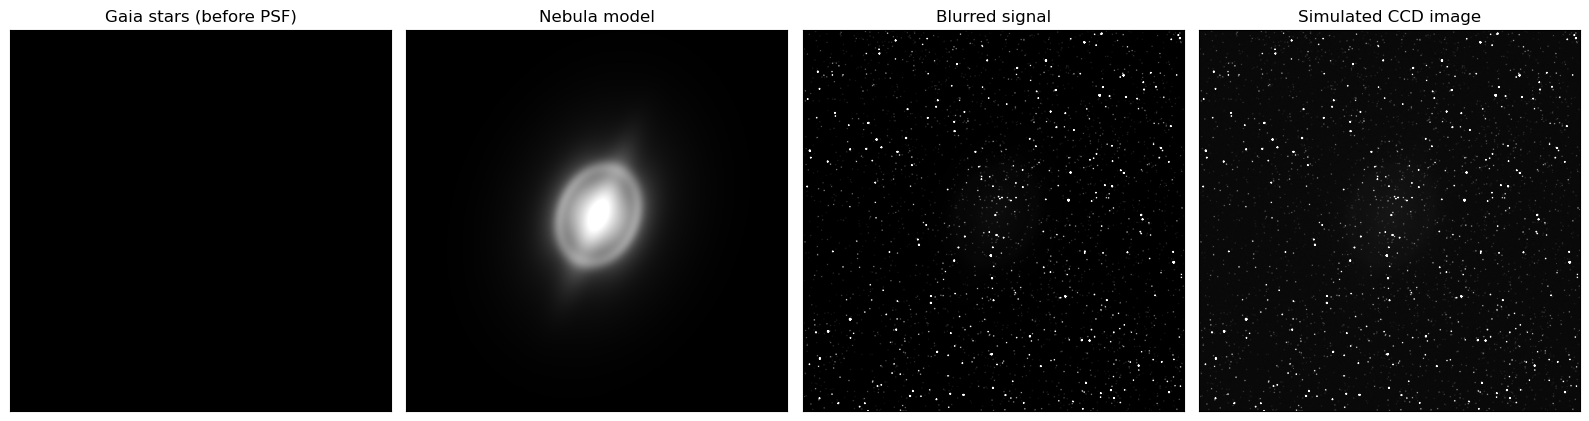

In [13]:
simulated, clean_signal = simulate_ccd(stars, nebula, nebula_peak, fwhm_px, background, noise,
                                      gain_e_per_adu=1.0, seed=42)

sim_header = wcs.to_header()
sim_header["OBJECT"] = "M27 simulated"
sim_header["FILTER"] = header.get("FILTER", "I").strip()
sim_header["EXPTIME"] = header.get("EXPTIME", 60.0)
sim_header["TELESCOP"] = "Vidojevica 1.4 m (simulated)"
sim_header["COMMENT"] = "Gaia DR3 stars + M27 model + seeing + noise + detector effects"
fits.writeto("M27_simulated_CCD.fit", simulated.astype(np.float32), sim_header, overwrite=True)

layers = [(stars, "Gaia stars (before PSF)"), (nebula, "Nebula model"),
          (clean_signal, "Blurred signal"), (simulated, "Simulated CCD image")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, (img, title) in zip(axes, layers):
    lo, hi = display_limits(img)
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.set_xticks([]), ax.set_yticks([])
fig.tight_layout()
fig.savefig(FIGURES / "simulation_steps.png", dpi=110, bbox_inches="tight")
plt.show()

## 7. Compare with the real image

Both images share the same pixel grid (the simulation uses the real WCS), so no resizing or shifting is
needed. They are normalised the same way before the comparison.

Most pixels contain only sky, and the noise in two different images never matches, so raw
pixel-by-pixel metrics mostly measure noise. Both images are therefore smoothed by about the size of a
star before computing the metrics, and the correlation is also reported for the pixels that actually
contain light from stars or the nebula (`correlation_signal`).

- **SSIM**: structural similarity (1 = identical).
- **Correlation**: Pearson correlation of pixel values (1 = perfect linear match, 0 = unrelated).
- **RMSE** and residual statistics on the normalised, smoothed images.

Pixels with star or nebula light: 5.3%
               ssim: 0.8906
               rmse: 0.0303
        correlation: 0.9156
      residual_mean: -0.0031
       residual_std: 0.0302
 correlation_signal: 0.9239


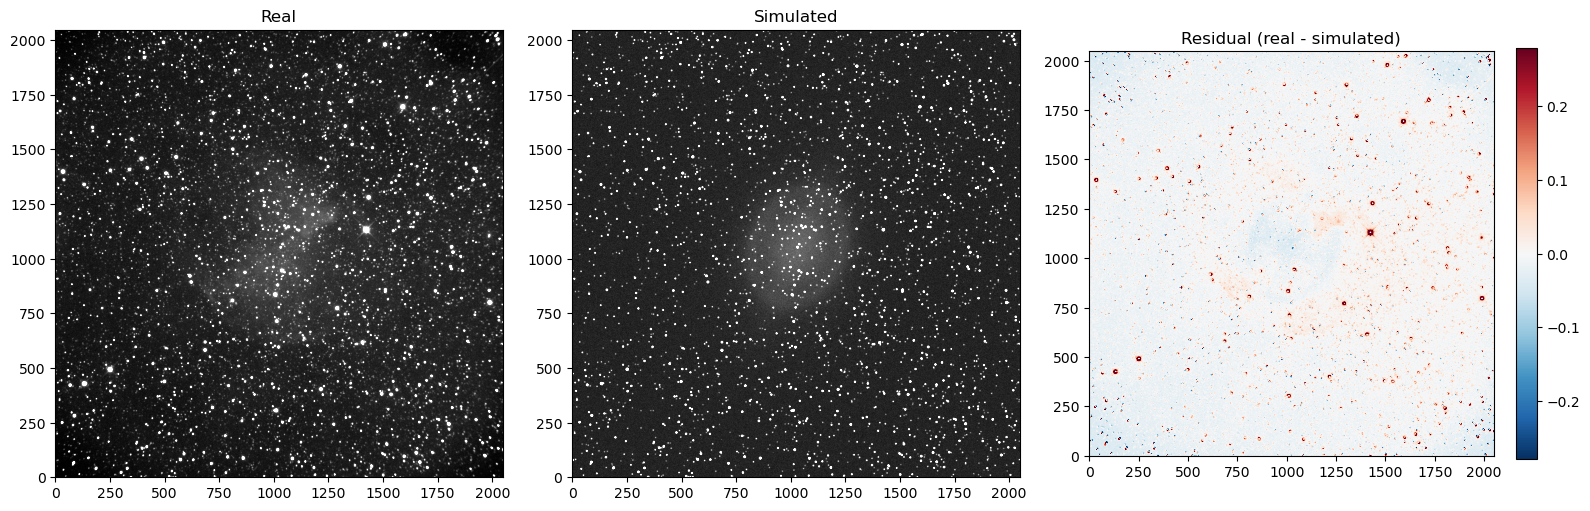

In [15]:
real_norm = normalize_image(real)
sim_norm = normalize_image(simulated)
signal_mask = clean_signal > 2 * noise
metrics = compare_images(real_norm, sim_norm, smooth_sigma=fwhm_px / 2.355, signal_mask=signal_mask)
residual = real_norm - sim_norm

print(f"Pixels with star or nebula light: {signal_mask.mean():.1%}")
for name, value in metrics.items():
    print(f"{name:>19}: {value:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.3))
for ax, img, title in zip(axes[:2], [real_norm, sim_norm], ["Real", "Simulated"]):
    ax.imshow(img, origin="lower", cmap="gray", vmin=0, vmax=0.3)
    ax.set_title(title)
lim = np.percentile(np.abs(residual), 99.5)
im = axes[2].imshow(residual, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("Residual (real - simulated)")
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES / "comparison.png", dpi=110, bbox_inches="tight")
plt.show()

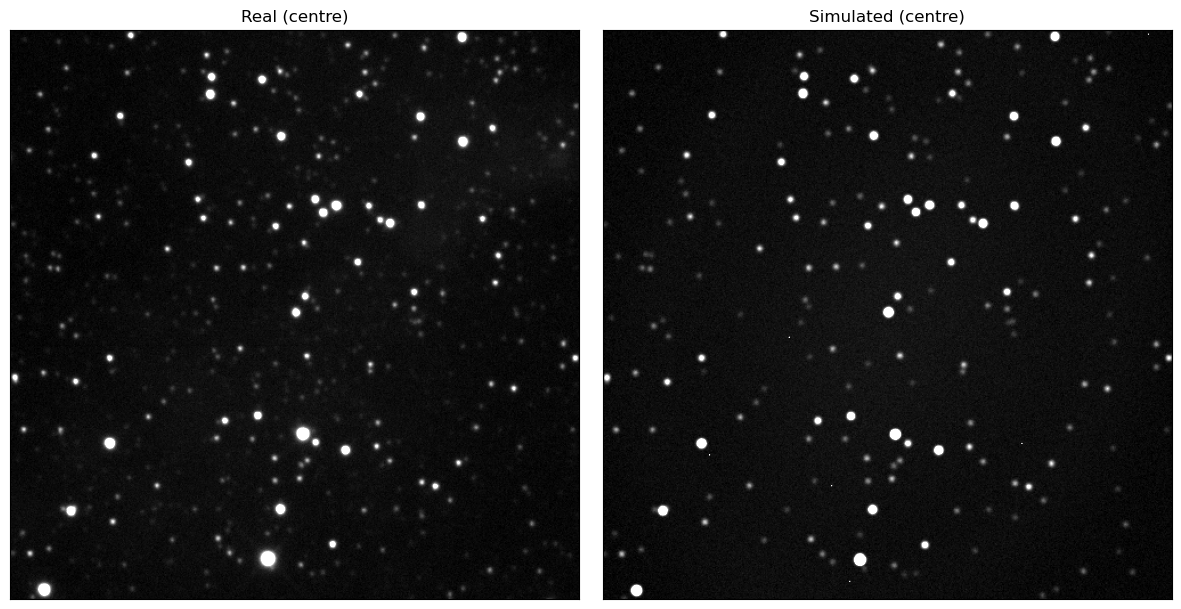

In [16]:
# Close-up of the nebula's centre: stars should appear in the same places in both images.
half = 250
x0, y0 = int(cx), int(cy)
box = (slice(max(y0 - half, 0), y0 + half), slice(max(x0 - half, 0), x0 + half))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in zip(axes, [real, simulated], ["Real (centre)", "Simulated (centre)"]):
    lo, hi = display_limits(img[box], 1, 99.5)
    ax.imshow(img[box], origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.set_xticks([]), ax.set_yticks([])
fig.tight_layout()
fig.savefig(FIGURES / "zoom.png", dpi=110, bbox_inches="tight")
plt.show()

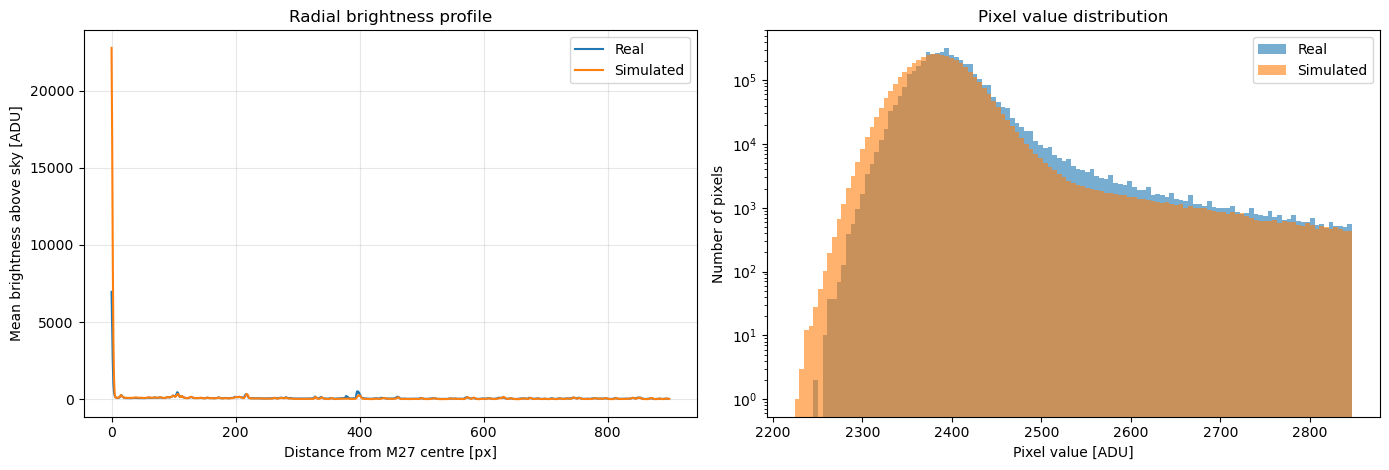

In [17]:
prof_real = radial_profile(real - background, (cx, cy))
prof_sim = radial_profile(simulated - background, (cx, cy))
n = min(len(prof_real), len(prof_sim), 900)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(prof_real[:n], label="Real")
axes[0].plot(prof_sim[:n], label="Simulated")
axes[0].set(xlabel="Distance from M27 centre [px]", ylabel="Mean brightness above sky [ADU]",
            title="Radial brightness profile")
axes[0].legend()
axes[0].grid(alpha=0.3)

bins = np.linspace(background - 5 * noise, background + 15 * noise, 120)
axes[1].hist(real.ravel(), bins=bins, alpha=0.6, label="Real")
axes[1].hist(simulated.ravel(), bins=bins, alpha=0.6, label="Simulated")
axes[1].set(xlabel="Pixel value [ADU]", ylabel="Number of pixels", title="Pixel value distribution",
            yscale="log")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "profiles.png", dpi=110, bbox_inches="tight")
plt.show()

## 8. Image quality: real vs simulated

In [19]:
sim_background, sim_noise = estimate_background_noise(simulated)
xs_sim, ys_sim = detect_sources(simulated, sim_background, sim_noise)
sim_fwhm = estimate_fwhm(simulated, xs_sim, ys_sim)

rows = [
    ("Background [ADU]", background, sim_background),
    ("Noise [ADU]", noise, sim_noise),
    ("FWHM [arcsec]", fwhm_px * pixel_scale, sim_fwhm * pixel_scale),
    ("Detected stars", len(xs_real), len(xs_sim)),
]
print(f"{'':<18}{'Real':>10}{'Simulated':>12}")
for name, r, s in rows:
    print(f"{name:<18}{r:>10.2f}{s:>12.2f}")

results = {"metrics": metrics, "zero_point": zero_point, "calibration_stars": n_calib,
           "nebula_peak_adu": nebula_peak,
           "quality": {name: {"real": float(r), "simulated": float(s)} for name, r, s in rows}}
Path("results.json").write_text(json.dumps(results, indent=2))
print("\nSaved results.json")

                        Real   Simulated
Background [ADU]     2380.00     2382.27
Noise [ADU]            31.13       32.88
FWHM [arcsec]           1.65        1.59
Detected stars       2005.00     2023.00

Saved results.json


## 9. What the differences mean

Remaining differences come from the simplifications in the model:

- **Nebula shape**: the model is a smooth, hand-shaped approximation of M27, while the real nebula has
  filaments and knots.
- **Star brightness**: Gaia G magnitudes are converted to the I band with a single zero point and no
  colour term, so very red or blue stars come out too faint or too bright.
- **PSF**: a single Gaussian over the whole image; real stars have broader wings and may change shape
  across the field.
- **Detector**: the gain, hot-pixel rate and cosmic-ray count are assumptions, not measured values.